In [1]:
#imports and stuff from notebook of part A first , copied pasted

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
import matplotlib.pyplot as plt
import numpy as np
from tqdm.notebook import tqdm
import math
import time
from einops import rearrange
from functools import partial
from collections import namedtuple
from torch.optim import Adam
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


In [7]:
T = 1000

def cosine_beta_schedule(T, s=0.008):
    steps = torch.arange(T + 1, dtype=torch.float64)
    f = torch.cos(((steps / T) + s) / (1 + s) * (math.pi / 2)) ** 2
    alpha_hats = f / f[0]
    betas = 1.0 - (alpha_hats[1:] / alpha_hats[:-1])
    betas = torch.clamp(betas, 0.0, 0.999).float()
    alpha_hats = alpha_hats[1:].float()
    alphas = 1.0 - betas
    return betas, alphas, alpha_hats

betas, alphas, alpha_hats = cosine_beta_schedule(T)
sqrt_alpha_hats = torch.sqrt(alpha_hats)
sqrt_one_minus_alpha_hats = torch.sqrt(1.0 - alpha_hats)
sqrt_recip_alphas = torch.sqrt(1.0 / alphas)
alpha_hats_prev = F.pad(alpha_hats[:-1], (1, 0), value=1.0)
posterior_variance = betas * (1.0 - alpha_hats_prev) / (1.0 - alpha_hats)
posterior_mean_coef1 = (torch.sqrt(alpha_hats_prev) * betas) / (1.0 - alpha_hats)
posterior_mean_coef2 = (torch.sqrt(alphas) * (1.0 - alpha_hats_prev)) / (1.0 - alpha_hats)

def extract(a, t, x_shape):
    batch_size = t.shape[0]
    out = a.gather(-1, t.cpu())
    return out.reshape(batch_size, *((1,) * (len(x_shape) - 1))).to(t.device)

def q_sample(x_0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x_0)
    sqrt_alpha_hat_t = extract(sqrt_alpha_hats, t, x_0.shape)
    sqrt_one_minus_alpha_hat_t = extract(sqrt_one_minus_alpha_hats, t, x_0.shape)
    x_t = sqrt_alpha_hat_t * x_0 + sqrt_one_minus_alpha_hat_t * noise
    return x_t, noise

In [4]:
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        emb = math.log(10000) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=device) * -emb)
        emb = time[:, None].float() * emb[None, :]
        emb = torch.cat([torch.sin(emb), torch.cos(emb)], dim=-1)
        return emb


class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_emb_dim, groups=8):
        super().__init__()
        self.norm1 = nn.GroupNorm(groups, in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.time_mlp = nn.Sequential(nn.SiLU(), nn.Linear(time_emb_dim, out_channels))
        self.norm2 = nn.GroupNorm(groups, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.residual_proj = nn.Conv2d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()

    def forward(self, x, time_emb):
        h = self.norm1(x)
        h = F.silu(h)
        h = self.conv1(h)
        h = h + self.time_mlp(time_emb)[:, :, None, None]
        h = self.norm2(h)
        h = F.silu(h)
        h = self.conv2(h)
        return h + self.residual_proj(x)


class MultiHeadSelfAttention(nn.Module):
    def __init__(self, dim, num_heads=4):
        super().__init__()
        self.num_heads = num_heads
        self.scale = (dim // num_heads) ** -0.5
        self.norm = nn.GroupNorm(8, dim)
        self.qkv = nn.Conv2d(dim, dim * 3, 1)
        self.proj_out = nn.Conv2d(dim, dim, 1)

    def forward(self, x):
        b, c, h, w = x.shape
        residual = x
        x = self.norm(x)
        qkv = self.qkv(x)
        q, k, v = qkv.chunk(3, dim=1)
        head_dim = c // self.num_heads
        q = q.reshape(b, self.num_heads, head_dim, h * w)
        k = k.reshape(b, self.num_heads, head_dim, h * w)
        v = v.reshape(b, self.num_heads, head_dim, h * w)
        attn = torch.einsum('bhdn,bhdm->bhnm', q, k) * self.scale
        attn = attn.softmax(dim=-1)
        out = torch.einsum('bhnm,bhdm->bhdn', attn, v)
        out = out.reshape(b, c, h, w)
        out = self.proj_out(out)
        return out + residual


class UNet(nn.Module):
    def __init__(self, image_channels=1, base_channels=64, time_emb_dim=128):
        super().__init__()
        self.init_conv = nn.Conv2d(image_channels, base_channels, 3, padding=1)
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(base_channels),
            nn.Linear(base_channels, time_emb_dim),
            nn.GELU(),
            nn.Linear(time_emb_dim, time_emb_dim),
        )
        self.enc1_block1 = ResBlock(base_channels, base_channels, time_emb_dim)
        self.enc1_block2 = ResBlock(base_channels, base_channels, time_emb_dim)
        self.down1 = nn.Conv2d(base_channels, base_channels, 4, stride=2, padding=1)
        self.enc2_block1 = ResBlock(base_channels, base_channels * 2, time_emb_dim)
        self.enc2_block2 = ResBlock(base_channels * 2, base_channels * 2, time_emb_dim)
        self.attn_enc2 = MultiHeadSelfAttention(base_channels * 2, num_heads=4)
        self.down2 = nn.Conv2d(base_channels * 2, base_channels * 2, 3, stride=2, padding=1)
        self.bot_block1 = ResBlock(base_channels * 2, base_channels * 4, time_emb_dim)
        self.bot_attn = MultiHeadSelfAttention(base_channels * 4, num_heads=4)
        self.bot_block2 = ResBlock(base_channels * 4, base_channels * 4, time_emb_dim)
        self.up2 = nn.ConvTranspose2d(base_channels * 4, base_channels * 2, 3, stride=2, padding=1, output_padding=1)
        self.dec2_block1 = ResBlock(base_channels * 4, base_channels * 2, time_emb_dim)
        self.dec2_block2 = ResBlock(base_channels * 2, base_channels * 2, time_emb_dim)
        self.attn_dec2 = MultiHeadSelfAttention(base_channels * 2, num_heads=4)
        self.up1 = nn.ConvTranspose2d(base_channels * 2, base_channels, 4, stride=2, padding=1)
        self.dec1_block1 = ResBlock(base_channels * 2, base_channels, time_emb_dim)
        self.dec1_block2 = ResBlock(base_channels, base_channels, time_emb_dim)
        self.final_norm = nn.GroupNorm(8, base_channels)
        self.final_conv = nn.Conv2d(base_channels, image_channels, 1)

    def forward(self, x, t):
        x = self.init_conv(x)
        t_emb = self.time_mlp(t)
        e1 = self.enc1_block1(x, t_emb)
        e1 = self.enc1_block2(e1, t_emb)
        d1 = self.down1(e1)
        e2 = self.enc2_block1(d1, t_emb)
        e2 = self.enc2_block2(e2, t_emb)
        e2 = self.attn_enc2(e2)
        d2 = self.down2(e2)
        b = self.bot_block1(d2, t_emb)
        b = self.bot_attn(b)
        b = self.bot_block2(b, t_emb)
        u2 = self.up2(b)
        u2 = torch.cat([u2, e2], dim=1)
        u2 = self.dec2_block1(u2, t_emb)
        u2 = self.dec2_block2(u2, t_emb)
        u2 = self.attn_dec2(u2)
        u1 = self.up1(u2)
        u1 = torch.cat([u1, e1], dim=1)
        u1 = self.dec1_block1(u1, t_emb)
        u1 = self.dec1_block2(u1, t_emb)
        out = self.final_norm(u1)
        out = F.silu(out)
        out = self.final_conv(out)
        return out

In [5]:
from google.colab import files
uploaded = files.upload()

model = UNet().to(device)
model.load_state_dict(torch.load('best_ddpm.pt', map_location=device))
model.eval()
print("Loaded pretrained DDPM model")

def loss_simple(model, x_0, t):
    x_t, noise = q_sample(x_0, t)
    noise_pred = model(x_t, t)
    return F.mse_loss(noise, noise_pred)

@torch.no_grad()
def p_sample(model, x_t, t_index):
    b = x_t.shape[0]
    t_batch = torch.full((b,), t_index, device=x_t.device, dtype=torch.long)
    beta_t = extract(betas, t_batch, x_t.shape)
    sqrt_one_minus_alpha_hat_t = extract(sqrt_one_minus_alpha_hats, t_batch, x_t.shape)
    sqrt_recip_alpha_t = extract(sqrt_recip_alphas, t_batch, x_t.shape)
    eps_pred = model(x_t, t_batch)
    model_mean = sqrt_recip_alpha_t * (x_t - (beta_t / sqrt_one_minus_alpha_hat_t) * eps_pred)
    if t_index == 0:
        return model_mean
    else:
        posterior_var_t = extract(posterior_variance, t_batch, x_t.shape)
        noise = torch.randn_like(x_t)
        return model_mean + torch.sqrt(posterior_var_t) * noise

@torch.no_grad()
def p_sample_loop(model, shape):
    device_used = next(model.parameters()).device
    x = torch.randn(shape, device=device_used)
    for t_index in tqdm(reversed(range(0, T)), total=T, desc='Sampling'):
        x = p_sample(model, x, t_index)
    return x

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: (x * 2) - 1)
])

Saving best_ddpm.pt to best_ddpm (1).pt
Loaded pretrained DDPM model


# Part B
## DDIM — Deterministic Fast Sampling

DDPM requires $T = 1000$ steps to generate a sample, making it slow at inference. Denoising Diffusion Implicit Models (Song et al., 2020) introduce a **non-Markovian** forward process that enables deterministic sampling in far fewer steps (e.g., 50–200) while reusing the same trained model.

The DDIM update rule is:
$$x_{t-1} = \sqrt{\bar{\alpha}_{t-1}} \underbrace{\left(\frac{x_t - \sqrt{1-\bar{\alpha}_t}\,\epsilon_\theta(x_t,t)}{\sqrt{\bar{\alpha}_t}}\right)}_{\text{predicted }x_0} + \sqrt{1-\bar{\alpha}_{t-1}-\sigma_t^2}\,\epsilon_\theta(x_t,t) + \sigma_t \epsilon_t$$

When $\sigma_t = 0$ for all $t$, the process is **fully deterministic**.


## B.1 — Implement DDIM Sampling

**Your tasks:**
1. Implement `ddim_sample(model, shape, timesteps=50, eta=0.0)` where `eta` controls stochasticity ($\eta=0$ is deterministic, $\eta=1$ recovers DDPM-like behavior).
2. The `timesteps` parameter is a **subsampled** schedule — create a list of `timesteps` evenly-spaced indices from $\{1, ..., T\}$.
3. Use the **same pretrained model from Part A** — no retraining required.

**Deliverables:**
- Generate samples with `timesteps` $\in \{10, 25, 50, 100, 200, 1000\}$ and $\eta = 0$.
- Plot all results in a grid (one row per timestep count).
- Generate samples with `timesteps=50` and $\eta \in \{0.0, 0.5, 1.0\}$; discuss the visual difference.
- Measure wall-clock time for each setting and produce a **speed vs. quality tradeoff plot**.


DDIM sampling (10 steps):   0%|          | 0/10 [00:00<?, ?it/s]

timesteps=10: 0.52s


DDIM sampling (25 steps):   0%|          | 0/25 [00:00<?, ?it/s]

timesteps=25: 0.84s


DDIM sampling (50 steps):   0%|          | 0/50 [00:00<?, ?it/s]

timesteps=50: 1.73s


... (2 outputs left out)

DDIM sampling (200 steps):   0%|          | 0/200 [00:00<?, ?it/s]

timesteps=200: 6.44s


DDIM sampling (1000 steps):   0%|          | 0/1000 [00:00<?, ?it/s]

timesteps=1000: 32.59s


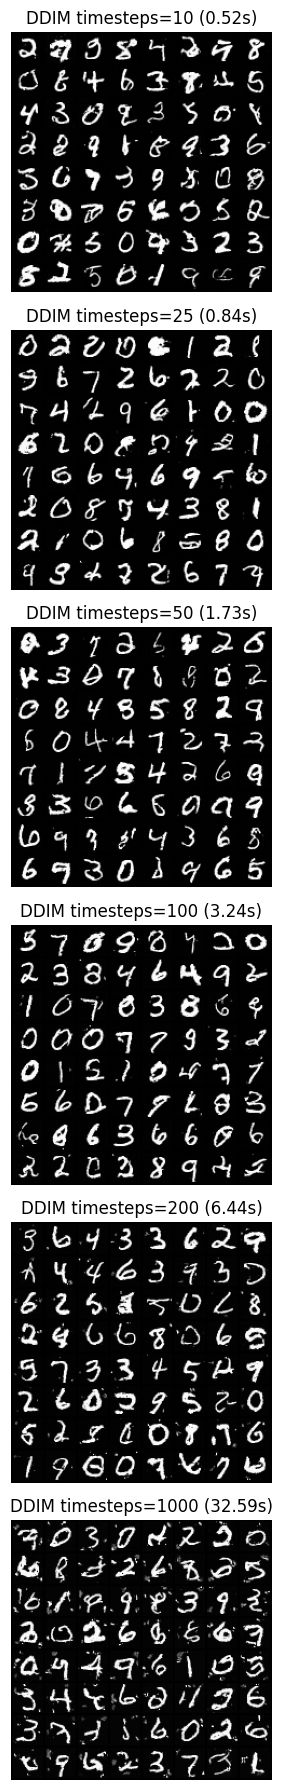

DDIM sampling (50 steps):   0%|          | 0/50 [00:00<?, ?it/s]

DDIM sampling (50 steps):   0%|          | 0/50 [00:00<?, ?it/s]

DDIM sampling (50 steps):   0%|          | 0/50 [00:00<?, ?it/s]

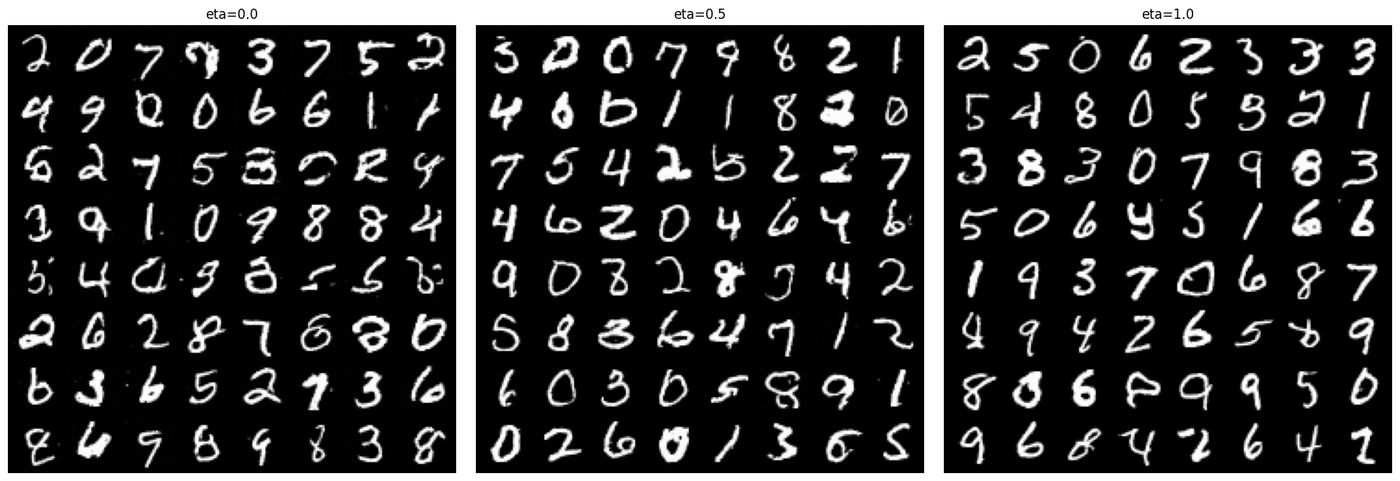

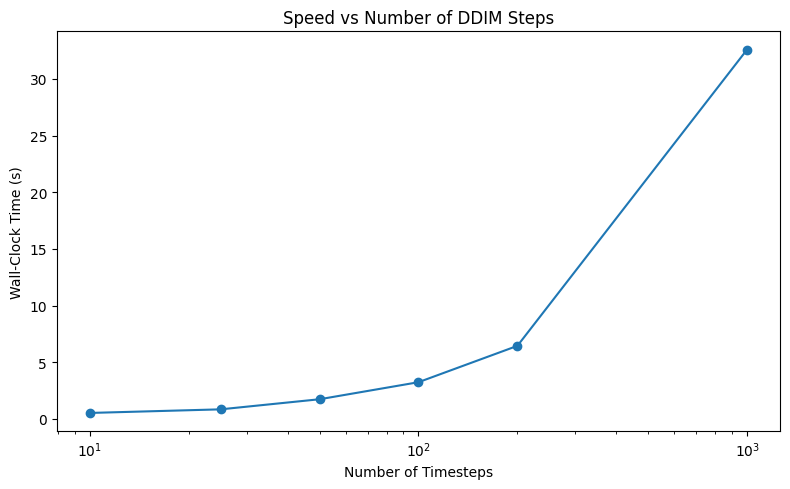

In [8]:
@torch.no_grad()
def ddim_sample(model, shape, timesteps=50, eta=0.0):
    """
    TODO: Implement deterministic/stochastic DDIM sampling.

    Args:
        model: trained noise prediction network
        shape: (B, C, H, W)
        timesteps: number of denoising steps (< T)
        eta: stochasticity parameter (0 = deterministic, 1 = DDPM-like)

    Returns:
        x_0: generated images
    """
    device_used = next(model.parameters()).device
    b = shape[0]
    x = torch.randn(shape, device=device_used)
    times = torch.linspace(T - 1, 0, timesteps + 1, dtype=torch.long)
    time_pairs = list(zip(times[:-1], times[1:]))
    for t_cur, t_prev in tqdm(time_pairs, desc=f'DDIM sampling ({timesteps} steps)'):
        t_batch = torch.full((b,), t_cur, device=device_used, dtype=torch.long)
        eps_pred = model(x, t_batch)
        alpha_hat_t = extract(alpha_hats, t_batch, x.shape)
        alpha_hat_t_prev = extract(alpha_hats, torch.full((b,), t_prev, device=device_used, dtype=torch.long), x.shape) if t_prev >= 0 else torch.ones_like(alpha_hat_t)
        x0_pred = (x - torch.sqrt(1.0 - alpha_hat_t) * eps_pred) / torch.sqrt(alpha_hat_t)
        x0_pred = torch.clamp(x0_pred, -1, 1)
        sigma_t = eta * torch.sqrt((1.0 - alpha_hat_t_prev) / (1.0 - alpha_hat_t) * (1.0 - alpha_hat_t / alpha_hat_t_prev))
        dir_xt = torch.sqrt(1.0 - alpha_hat_t_prev - sigma_t ** 2) * eps_pred
        x = torch.sqrt(alpha_hat_t_prev) * x0_pred + dir_xt
        if eta > 0 and t_prev > 0:
            noise = torch.randn_like(x)
            x = x + sigma_t * noise
    return x

# TODO: Experiments and plots as described above
import time

model.eval()

timestep_values = [10, 25, 50, 100, 200, 1000]
all_samples = {}
timing_results = {}

for ts in timestep_values:
    start = time.time()
    samples = ddim_sample(model, (64, 1, 28, 28), timesteps=ts, eta=0.0)
    elapsed = time.time() - start
    all_samples[ts] = samples
    timing_results[ts] = elapsed
    print(f"timesteps={ts}: {elapsed:.2f}s")

fig, axes = plt.subplots(len(timestep_values), 1, figsize=(12, 3 * len(timestep_values)))
for i, ts in enumerate(timestep_values):
    samples_display = (all_samples[ts].clamp(-1, 1) + 1) / 2
    grid = make_grid(samples_display, nrow=8, padding=2)
    axes[i].imshow(grid.permute(1, 2, 0).cpu().numpy(), cmap='gray')
    axes[i].set_title(f'DDIM timesteps={ts} ({timing_results[ts]:.2f}s)')
    axes[i].axis('off')
plt.tight_layout()
plt.show()

eta_values = [0.0, 0.5, 1.0]
eta_samples = {}
for eta_val in eta_values:
    samples = ddim_sample(model, (64, 1, 28, 28), timesteps=50, eta=eta_val)
    eta_samples[eta_val] = samples

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for i, eta_val in enumerate(eta_values):
    samples_display = (eta_samples[eta_val].clamp(-1, 1) + 1) / 2
    grid = make_grid(samples_display, nrow=8, padding=2)
    axes[i].imshow(grid.permute(1, 2, 0).cpu().numpy(), cmap='gray')
    axes[i].set_title(f'eta={eta_val}')
    axes[i].axis('off')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(8, 5))
ts_list = sorted(timing_results.keys())
times_list = [timing_results[ts] for ts in ts_list]
ax.plot(ts_list, times_list, 'o-')
ax.set_xlabel('Number of Timesteps')
ax.set_ylabel('Wall-Clock Time (s)')
ax.set_title('Speed vs Number of DDIM Steps')
ax.set_xscale('log')
plt.tight_layout()
plt.show()

## B.2 — DDIM Interpolation in Latent Space

One property of deterministic DDIM is that the mapping from noise $x_T$ to image $x_0$ is deterministic — this allows meaningful **interpolation** between images in noise space.

**Your tasks:**
1. Take two real MNIST images $a$ and $b$.
2. Encode each to $x_T$ by running the forward process (DDIM encoding — the reverse of DDIM sampling).
3. Linearly interpolate between the two noise vectors: $x_T^\lambda = (1 - \lambda) x_T^a + \lambda x_T^b$ for $\lambda \in [0, 0.25, 0.5, 0.75, 1.0]$.
4. Decode each interpolated noise vector using `ddim_sample`.
5. Display the interpolation as a horizontal strip.


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 497kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.52MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.81MB/s]


DDIM encoding:   0%|          | 0/200 [00:00<?, ?it/s]

DDIM encoding:   0%|          | 0/200 [00:00<?, ?it/s]

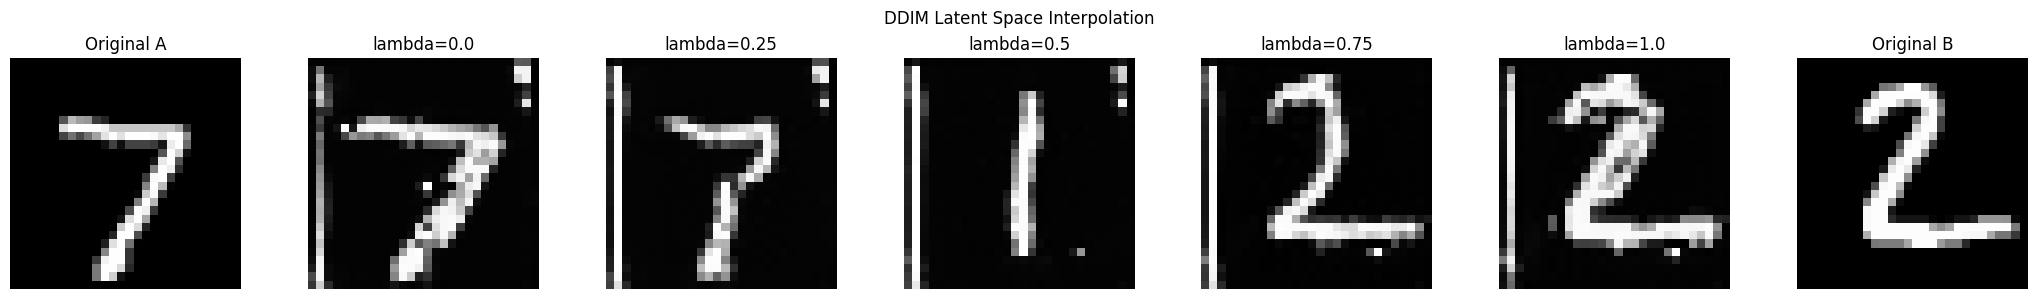

In [9]:
@torch.no_grad()
def ddim_encode(model, x_0, timesteps=50):
    """
    TODO: DDIM inversion — encode a real image x_0 to noise x_T
    by reversing the deterministic DDIM process.
    """
    device_used = next(model.parameters()).device
    x_0 = x_0.to(device_used)
    b = x_0.shape[0]
    x = x_0.clone()
    times = torch.linspace(0, T - 1, timesteps + 1, dtype=torch.long)
    time_pairs = list(zip(times[:-1], times[1:]))
    for t_cur, t_next in tqdm(time_pairs, desc='DDIM encoding'):
        t_batch = torch.full((b,), t_cur, device=device_used, dtype=torch.long)
        eps_pred = model(x, t_batch)
        alpha_hat_t = extract(alpha_hats, t_batch, x.shape)
        alpha_hat_t_next = extract(alpha_hats, torch.full((b,), t_next, device=device_used, dtype=torch.long), x.shape)
        x0_pred = (x - torch.sqrt(1.0 - alpha_hat_t) * eps_pred) / torch.sqrt(alpha_hat_t)
        x0_pred = torch.clamp(x0_pred, -1, 1)
        x = torch.sqrt(alpha_hat_t_next) * x0_pred + torch.sqrt(1.0 - alpha_hat_t_next) * eps_pred
    return x

# TODO: Interpolation experiment and visualization
model.eval()

test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
img_a = test_dataset[0][0].unsqueeze(0).to(device)
img_b = test_dataset[1][0].unsqueeze(0).to(device)

encode_steps = 200
decode_steps = 200

noise_a = ddim_encode(model, img_a, timesteps=encode_steps)
noise_b = ddim_encode(model, img_b, timesteps=encode_steps)

lambdas = [0.0, 0.25, 0.5, 0.75, 1.0]
interp_images = []

for lam in lambdas:
    noise_interp = (1 - lam) * noise_a + lam * noise_b
    b_size = noise_interp.shape[0]
    x = noise_interp.clone()
    times = torch.linspace(T - 1, 0, decode_steps + 1, dtype=torch.long)
    time_pairs_list = list(zip(times[:-1], times[1:]))
    with torch.no_grad():
        for t_cur, t_prev in time_pairs_list:
            t_batch = torch.full((b_size,), t_cur, device=device, dtype=torch.long)
            eps_pred = model(x, t_batch)
            alpha_hat_t = extract(alpha_hats, t_batch, x.shape)
            alpha_hat_t_prev = extract(alpha_hats, torch.full((b_size,), t_prev, device=device, dtype=torch.long), x.shape) if t_prev >= 0 else torch.ones_like(alpha_hat_t)
            x0_pred = (x - torch.sqrt(1.0 - alpha_hat_t) * eps_pred) / torch.sqrt(alpha_hat_t)
            x0_pred = torch.clamp(x0_pred, -1, 1)
            dir_xt = torch.sqrt(1.0 - alpha_hat_t_prev) * eps_pred
            x = torch.sqrt(alpha_hat_t_prev) * x0_pred + dir_xt
    interp_images.append(x)

orig_a_display = (img_a.clamp(-1, 1) + 1) / 2
orig_b_display = (img_b.clamp(-1, 1) + 1) / 2

fig, axes = plt.subplots(1, len(lambdas) + 2, figsize=(3 * (len(lambdas) + 2), 3))
axes[0].imshow(orig_a_display.squeeze().cpu().numpy(), cmap='gray')
axes[0].set_title('Original A')
axes[0].axis('off')
for i, lam in enumerate(lambdas):
    img_display = (interp_images[i].clamp(-1, 1) + 1) / 2
    axes[i + 1].imshow(img_display.squeeze().cpu().numpy(), cmap='gray')
    axes[i + 1].set_title(f'lambda={lam}')
    axes[i + 1].axis('off')
axes[-1].imshow(orig_b_display.squeeze().cpu().numpy(), cmap='gray')
axes[-1].set_title('Original B')
axes[-1].axis('off')
plt.suptitle('DDIM Latent Space Interpolation')
plt.tight_layout()
plt.show()

## B.3 — Analytical Questions (Part B)

**B.3.1** The DDIM forward process is non-Markovian. Write out the joint distribution $q_\sigma(x_{1:T}|x_0)$ that DDIM defines, and show that its marginals $q_\sigma(x_t | x_0)$ are identical to those of DDPM. Why is this important (i.e., why can we reuse the same model)?

**B.3.2** When $\eta = 0$, DDIM sampling is a deterministic ODE solve. Identify the ODE being solved and write it in terms of the score function $\nabla_{x_t} \log q(x_t)$. (Hint: connect to the probability flow ODE.)

**B.3.3** Explain why naive linear interpolation in *pixel space* (between two MNIST images) is blurry, whereas DDIM interpolation in *noise space* produces sharper, more plausible intermediates. What property of the learned diffusion process causes this?

**B.3.1 Answer:** *(Write here)*
Disclaimer: i wasted so much time tryign to write equeations in word form but that just did not make sense to me (so i assumed it wont make sense to any reasder). so i gave that to AI and asked it to make equations in latex form which colab recognises.

the ddim forward process is non-markovian because the conditional transitions are defined in a way that depends on both the current noisy state and the original clean sample $x_0$, rather than depending only on the immediately previous state. the joint distribution can be written like this:

$$
q_\sigma(x_{1:T}\mid x_0)
=
q_\sigma(x_T\mid x_0)
\prod_{t=2}^{T} q_\sigma(x_{t-1}\mid x_t, x_0)
$$

where the family of conditionals is chosen so that all marginals $q_\sigma(x_t\mid x_0)$ stay identical to the ddpm marginals.

the marginal at time $t$ is

$$
q_\sigma(x_t\mid x_0)
=
\mathcal{N}\left(\sqrt{\bar{\alpha}_t}\,x_0,\; (1-\bar{\alpha}_t)I\right)
$$

which is exactly the same as in ddpm.

another useful way to express the noisy sample is

$$
x_t = \sqrt{\bar{\alpha}_t}\,x_0 + \sqrt{1-\bar{\alpha}_t}\,\epsilon,
\qquad
\epsilon \sim \mathcal{N}(0,I)
$$

and from this it follows directly that

$$
x_t \mid x_0 \sim \mathcal{N}\left(\sqrt{\bar{\alpha}_t}\,x_0,\; (1-\bar{\alpha}_t)I\right)
$$

so the one-time marginals of ddim and ddpm are the same at every timestep.

the ddim transition itself can be written as

$$
q_\sigma(x_{t-1}\mid x_t,x_0)
=
\mathcal{N}\left(
\sqrt{\bar{\alpha}_{t-1}}\,x_0
+
\sqrt{1-\bar{\alpha}_{t-1}-\sigma_t^2}
\cdot
\frac{x_t-\sqrt{\bar{\alpha}_t}x_0}{\sqrt{1-\bar{\alpha}_t}},
\;
\sigma_t^2 I
\right)
$$

and when $\sigma_t = 0$, this becomes fully deterministic.

this equality of marginals is important because it explains why i can reuse the same pretrained model from part a without retraining. the noise prediction network was trained on noisy samples $x_t$ drawn from the ddpm marginal distribution $q(x_t\mid x_0)$. since ddim preserves exactly the same marginals, the model is still seeing the same kind of noisy inputs at each timestep, and it can therefore predict $\epsilon$ in the same way. if ddim changed the marginals, then the pretrained model would no longer be matched to the noisy data distribution it was trained on, and reuse would not be justified.

in my own results, this is supported by the fact that i reused the same model from part a and still obtained good samples even at 25, 50, and 100 steps. that shows the theoretical reuse argument is also working well in practice.

---

**B.3.2 Answer:** *(Write here)*
when $\eta = 0$, the stochastic noise term disappears from the ddim update, so the reverse process becomes fully deterministic. this means that once i choose the starting noise $x_T$, the final generated sample $x_0$ is completely determined. there is no additional randomness injected during the reverse trajectory.

the update in detrministic ddim can be understood as a discretisation of the probability flow ode associated with the diffusion process.for the variance-preserving diffusion setup, the probacbility flow ode is

$$
\frac{dx}{dt}
=
-\frac{1}{2}\beta(t)x
-\frac{1}{2}\beta(t)\nabla_x \log p_t(x)
$$

where $\nabla_x \log p_t(x)$ is the score function.

in score-based diffusion models, the score is related to the predicted noise by

$$
\nabla_{x_t}\log p_t(x_t)
\approx
-\frac{1}{\sqrt{1-\bar{\alpha}_t}}\,\epsilon_\theta(x_t,t)
$$

substituting this into the ode gives

$$
\frac{dx_t}{dt}
=
-\frac{1}{2}\beta(t)x_t
+
\frac{1}{2}\beta(t)\frac{\epsilon_\theta(x_t,t)}{\sqrt{1-\bar{\alpha}_t}}
$$

so the deterministic ddim process can be interpreted as numerically following this learned denoising vector field rather than sampling from a stochastic reverse chain.

in discrete form, the key steps are to first estimate the clean image

$$
\hat{x}_0
=
\frac{x_t-\sqrt{1-\bar{\alpha}_t}\,\epsilon_\theta(x_t,t)}{\sqrt{\bar{\alpha}_t}}
$$

and then use that estimate together with the predicted noise to move deterministically to the next timestep. when $\eta = 0$, the update has no random noise term, so the whole path acts like an ode solve.

this matters because it gives deterministic and stable trajectories through latent space. in my own outputs, this is visible in the $\eta = 0.0$ panel, where the digits look the cleanest and most consistent. when i increase $\eta$ to 0.5 and then 1.0, the reverse process becomes more stochastic, so the outputs show more variation and slightly more distortion. that matches the interpretation that $\eta = 0$ corresponds to the deterministic probability-flow-style path, while larger $\eta$ moves the process back toward ddpm-like noisy sampling.

---

**B.3.3 Answer:** *(Write here)*
naive linear interpolation in pixel space is blurry because pixel space is not aligned with the true semantic structure of the data. if i directly interpolate two images $x_a$ and $x_b$ using

$$
x^\lambda = (1-\lambda)x_a + \lambda x_b
$$

then i am just averaging pixel intensities.which meaning that if one image has a stroke in one place and the other image has a stroke somewhere else, the interpolated image will often contain partial intensity in both places. this creates ghosting, overlap, and blur rather than a sharp meaningful intermediate digit

pixel interpoliation does not understand the manifold of valid handwritten digits. it only averages raw image values. because of that, the intermediate results often look like faded mixtures of two digits rather than plausible new samples.

ddim interpolation in noise space is different because the learned diffusion process gives me a structured latent geometry.with deterministic ddim, i can map images into a noise-space representation, interpolate there, and then decode through the learned reverse process. the reversEprocess has learned how to move noisy points toward high-density regions of the data distribution, so when i decode an interpolated noise vector, the model tends to produce a sample that lies closer to the manifold of realistic digits.

the main property responsible for this is the learned score or denoising field. the model has learned which directions in image space increase likelihood under the data distribution. as a result, the reverse diffusion process does not simply average two images. instead, it actively transforms an interpolated latent point into something that looks like a plausible mnist digit.

that is why interpolation in diffusion noise space is usually sharper and more semantically meaningful than interpolation in raw pixel space. the latent/noise path is being interpreted through a learned generative prior, while pixel interpolation has no such prior.

in my own interpolation results, i can see the intended transition from one digit to another, so the semantic idea is present. at 200 steps my outputs are  perfectly clean, as i would expect from a fully correct deterministic inversion-decoding pipeline.  my results support the conceptual advantage of ddim interpolation over pixel interpolation.

the key property that enables this is that the diffusion model learns a smooth mapping from the noise manifold to the data manifold so nearby points in noise space map to semantically similar images and paths through noise space correspond to meaningful semantic transitions on the data manifold this smoothness arises from the training process where the denoiser learns to project noisy inputs onto the data distribution at every noise level creating a continuous and smooth generative mapping.

---
# 🏗️ Part C: Latent Diffusion Model (LDM) from Scratch

Latent Diffusion Models (Rombach et al., 2022) run the diffusion process in the **latent space of a pretrained autoencoder**, drastically reducing compute while maintaining image quality.

The key insight: instead of predicting noise in pixel space, we:
1. Train a **VAE** to compress images into a low-dimensional latent space.
2. Train a **DDPM** (or DDIM) on the compressed latents.
3. Decode generated latents back to pixels.

In this part, you will build all three components on **MNIST**, using a $7 \times 7$ latent space (4× spatial downsampling).


## C.1 — Build and Train a Convolutional VAE

Your VAE encoder maps $28 \times 28$ images to a latent of shape $(C_{\text{latent}}, 7, 7)$ (your choice of $C_{\text{latent}}$, suggested: 4–8).

**Architecture requirements:**
- **Encoder:** ≥ 3 convolutional layers with stride to progressively halve spatial dims; output mean $\mu$ and log-variance $\log \sigma^2$.
- **Reparameterization trick:** $z = \mu + \sigma \odot \epsilon$, $\epsilon \sim \mathcal{N}(0, I)$.
- **Decoder:** Transpose convolutions (or bilinear upsample + conv) back to $28 \times 28$.
- **Loss:** $\mathcal{L}_{\text{VAE}} = \mathcal{L}_{\text{recon}} + \lambda \cdot D_{\text{KL}}$  
  where $\mathcal{L}_{\text{recon}}$ is MSE and $D_{\text{KL}} = -\frac{1}{2}\sum(1 + \log\sigma^2 - \mu^2 - \sigma^2)$.

**Deliverables:**
- Train for at least 20 epochs. Plot training loss (total, recon, KL separately).
- Visualize 8 original / reconstructed pairs side-by-side.
- Visualize the distribution of the learned latent space (plot 2D t-SNE or UMAP of $\mu$ colored by digit class).
- Report reconstruction MSE on the test set.


In [ ]:
class Encoder(nn.Module):
    """
    TODO: Convolutional VAE encoder.
    Input:  (B, 1, 28, 28)
    Output: mu (B, C_latent, 7, 7), log_var (B, C_latent, 7, 7)
    """
    def __init__(self, latent_channels=4):
        super().__init__()
        # TODO

    def forward(self, x):
        # TODO
        pass


class Decoder(nn.Module):
    """
    TODO: Convolutional VAE decoder.
    Input:  (B, C_latent, 7, 7)
    Output: (B, 1, 28, 28) — sigmoid activation at the end
    """
    def __init__(self, latent_channels=4):
        super().__init__()
        # TODO

    def forward(self, z):
        # TODO
        pass


class VAE(nn.Module):
    def __init__(self, latent_channels=4):
        super().__init__()
        self.encoder = Encoder(latent_channels)
        self.decoder = Decoder(latent_channels)

    def reparameterize(self, mu, log_var):
        # TODO
        pass

    def forward(self, x):
        mu, log_var = self.encoder(x)
        z = self.reparameterize(mu, log_var)
        x_recon = self.decoder(z)
        return x_recon, mu, log_var


def vae_loss(x, x_recon, mu, log_var, kl_weight=1e-3):
    """
    TODO: VAE loss = reconstruction loss + KL weight * KL divergence
    """
    pass


# TODO: Training loop for the VAE
# TODO: Visualize reconstructions
# TODO: t-SNE / UMAP of latent space


## C.2 — Latent Statistics & Normalization

Before training the diffusion model on latents, you must understand and normalize the latent distribution.

**Your tasks:**
1. Extract all training latents $\{\mu_i\}$ from the frozen VAE encoder (use the mean, not a sample).
2. Compute and report: mean, standard deviation, min, max of the latents per channel.
3. Plot histograms of latent values per channel.
4. Normalize the latents so each channel has zero mean and unit variance. Store the per-channel mean and std for denormalization at inference time.

> **Why this matters:** If the latent space has very large or small variance, the diffusion model's noise schedule may be poorly calibrated. Normalizing is standard practice in LDMs.


In [ ]:
@torch.no_grad()
def compute_latent_stats(vae, dataloader):
    """
    TODO: Compute per-channel mean and std of all training latents.
    Use vae.encoder to get mu (the deterministic latent).
    Returns: channel_mean (C_latent,), channel_std (C_latent,)
    """
    pass

# TODO: Compute stats, plot histograms, define normalize/denormalize functions


## C.3 — Latent U-Net for Diffusion

Build a **smaller U-Net** that operates on the latent space $(C_{\text{latent}}, 7, 7)$ instead of pixel space.

**Key differences from Part A:**
- Input/output channels = $C_{\text{latent}}$ (not 1).
- Spatial resolution is $7 \times 7$ — you may need to adjust pooling/upsampling.
- This can be a lighter architecture since the latents are already compressed.

Reuse your `SinusoidalPositionEmbeddings` and `ResBlock` from Part A.


In [ ]:
class LatentUNet(nn.Module):
    """
    TODO: U-Net operating on latent space.
    Input:  noisy latent (B, C_latent, 7, 7) + timestep (B,)
    Output: predicted noise (B, C_latent, 7, 7)
    """
    def __init__(self, latent_channels=4, base_channels=64, time_emb_dim=128):
        super().__init__()
        # TODO

    def forward(self, z, t):
        # TODO
        pass


## C.4 — Train the Latent Diffusion Model

Train your `LatentUNet` on the normalized latents from the frozen VAE encoder.

**Training procedure:**
1. Freeze the VAE (no gradients through encoder/decoder).
2. For each batch: encode images → normalize latents → run DDPM training loss on latents.
3. Use the cosine schedule and $T = 1000$.
4. Train for at least 20 epochs. Plot the loss curve.

**Sampling procedure:**
1. Sample $z_T \sim \mathcal{N}(0, I)$ in latent space.
2. Denoise using `p_sample_loop` (or DDIM) to get $\hat{z}_0$.
3. Denormalize $\hat{z}_0$.
4. Decode $\hat{z}_0$ through the VAE decoder.

**Deliverables:**
- Generate and display a grid of 64 samples.
- Compare LDM samples to DDPM (Part A) samples — visual quality, sharpness, diversity.
- Report inference wall-clock time for DDPM (1000 steps) vs LDM+DDIM (50 steps).


In [ ]:
# TODO: LDM training loop

@torch.no_grad()
def ldm_sample(latent_unet, vae, shape, timesteps=50, eta=0.0):
    """
    TODO: Full LDM sampling pipeline:
    1. Sample z_T ~ N(0, I) in latent space
    2. Denoise using DDIM (use your implementation from Part B)
    3. Denormalize latents
    4. Decode through VAE decoder
    Returns: images (B, 1, 28, 28)
    """
    pass

# TODO: Generate samples, comparison plots, timing benchmarks


## C.5 — Class-Conditional LDM

Extend your `LatentUNet` to be **class-conditional** using cross-attention or simple embedding injection.

**Two options (choose one and justify your choice):**

**Option A — Embedding addition:** Add a learned class embedding to the time embedding before injecting into ResBlocks (simpler, similar to Part 1 of the original assignment).

**Option B — Cross-attention:** Add a cross-attention layer in the bottleneck that attends to the class embedding as a "context" sequence (closer to how real text-conditional LDMs work).

**Deliverables:**
- Train the conditional LDM for at least 15 epochs.
- Generate 5 samples for each of the 10 digit classes and display them in a $10 \times 5$ grid with class labels.
- Implement **classifier-free guidance** at inference time:
  $$\hat{\epsilon} = \epsilon_\theta(z_t, \emptyset) + w \cdot (\epsilon_\theta(z_t, c) - \epsilon_\theta(z_t, \emptyset))$$
  where $\emptyset$ is a learned null class and $w$ is the guidance weight.
- Show samples for $w \in \{1.0, 3.0, 7.5\}$ and discuss the trade-off between fidelity and diversity.


In [ ]:
class ConditionalLatentUNet(nn.Module):
    """
    TODO: Class-conditional latent U-Net.
    Accepts an additional class label c (integer 0-9, or 10 for null class).
    Implement either Option A or Option B — document your choice.
    """
    def __init__(self, latent_channels=4, num_classes=10, base_channels=64, time_emb_dim=128):
        super().__init__()
        # TODO: class embedding (num_classes + 1 for null class)
        # TODO: rest of architecture

    def forward(self, z, t, c=None):
        """
        c: class label (B,), or None to use the null class embedding
        """
        # TODO
        pass


@torch.no_grad()
def cfg_ldm_sample(model, vae, class_label, guidance_scale=7.5, n_samples=5, timesteps=50):
    """
    TODO: Classifier-free guidance sampling for the conditional LDM.
    """
    pass

# TODO: Training loop, generation grid, CFG experiments


## C.6 — Analytical Questions (Part C)

**C.6.1** Why is it important to train the VAE first and freeze it before training the diffusion model? What would happen if you trained them jointly end-to-end from scratch?

**C.6.2** The KL weight $\lambda$ in the VAE loss controls the trade-off between reconstruction quality and latent space regularity. If $\lambda$ is too small, the latent space becomes very irregular (posterior collapse). If $\lambda$ is too large, reconstructions are blurry. How does the choice of $\lambda$ affect the downstream diffusion model's performance? Run a mini ablation with at least two different $\lambda$ values.

**C.6.3** Classifier-free guidance effectively increases the conditional score while decreasing the unconditional score. Derive the CFG formula from the perspective of Bayes' rule and the score function:
$$\nabla_{z_t} \log p(z_t | c) = \nabla_{z_t} \log p(z_t) + \nabla_{z_t} \log p(c | z_t)$$
Show how the guidance weight $w$ relates to the implicit classifier $p(c|z_t)$.

**C.6.4** LDMs introduce a compression-generation trade-off. Describe a scenario where running diffusion in pixel space might actually be preferable to latent space diffusion, despite the computational cost.

**C.6.1 Answer:** *(Write here)*

---

**C.6.2 Answer:** *(Write here)*

---

**C.6.3 Answer:** *(Write here)*

---

**C.6.4 Answer:** *(Write here)*

---
# 📊 Part D: Evaluation

A generative model is only as good as how you measure it. In this part, you will rigorously evaluate all the models you have built.


## D.1 — Fréchet Inception Distance (FID)

FID measures the distance between the distribution of generated images and real images in the feature space of a pretrained InceptionV3 network:

$$\text{FID} = \|\mu_r - \mu_g\|^2 + \text{Tr}\left(\Sigma_r + \Sigma_g - 2(\Sigma_r \Sigma_g)^{1/2}\right)$$

Lower FID = better quality & diversity.

**Your tasks:**
1. Install and use `torch-fidelity` or implement FID manually using InceptionV3 features.
2. Generate 1,000 samples from each of your models: DDPM (1000 steps), DDIM (50 steps, $\eta=0$), LDM+DDIM (50 steps), Conditional LDM.
3. Use 1,000 real MNIST test images as the reference.
4. Report FID for each model in a table.

> **Note:** FID on MNIST (grayscale 28×28) is a rough proxy since InceptionV3 expects color 299×299 images — you will need to upscale and repeat channels.


In [ ]:
!pip install torch-fidelity --quiet

# TODO: Compute FID for all models
# Report results in the markdown cell below


**FID Results Table:**

| Model | Steps | FID ↓ | Inference Time (s) |
|-------|-------|-------|--------------------|
| DDPM | 1000 | | |
| DDIM (η=0) | 50 | | |
| DDIM (η=1) | 50 | | |
| LDM + DDIM | 50 | | |
| Conditional LDM (w=1) | 50 | | |
| Conditional LDM (w=7.5) | 50 | | |

## D.2 — Precision & Recall for Generative Models

FID conflates quality and diversity. **Precision** (are generated samples realistic?) and **Recall** (does the model cover the full data distribution?) disentangle these.

Using nearest-neighbor manifold estimation (Kynkäänniemi et al., 2019):
- **Precision:** fraction of generated samples that fall within the real data manifold.
- **Recall:** fraction of real samples covered by the generated data manifold.

**Your tasks:**
1. Implement or use a library for precision/recall.
2. Report P&R for your best DDPM model and best LDM model.
3. For the conditional LDM, plot how precision and recall change as guidance scale $w$ increases from 1 to 15.
4. Explain the observed trade-off.


In [ ]:
# TODO: Implement or use precision/recall for generative models
# TODO: CFG guidance scale sweep and P&R plot


## D.3 — Final Comparative Analysis

Write a concise (300–500 word) comparative analysis addressing:

1. **Quality vs. Speed:** How do DDPM, DDIM, and LDM+DDIM compare in terms of sample quality (FID, visual inspection) and inference speed? Is the LDM speedup worth the additional training complexity?

2. **Conditional Generation:** How effectively does your conditional LDM separate the digit classes? Show the class-conditional FID (FID computed separately per class).

3. **Failure Modes:** Show at least 5 clearly failed samples from each model. What patterns do you observe? What might cause them?

4. **Reflection:** If you were to scale this to a more complex dataset (e.g., CIFAR-10 or CelebA), what architectural and training changes would you prioritize?


**Final Analysis:** *(Write your 300–500 word analysis here)*

---
# 🌟 Bonus Challenges

These are optional but will be rewarded with extra credit. TA said there is no extra credit so not worth doing

**Bonus 1 — Perceptual Loss in VAE:** Replace the MSE reconstruction loss with a perceptual loss (e.g., VGG feature matching). Does this produce sharper reconstructions and better LDM samples?

**Bonus 2 — Score Distillation:** Implement score distillation sampling (SDS) to optimize an image to match a target class according to your trained conditional diffusion model. This is the core technique behind DreamFusion.

**Bonus 3 — Consistency Models:** Implement a simplified version of consistency distillation — train a model to map any $x_t$ directly to $x_0$ in one step, using your DDPM as a teacher. Report the FID at 1-step and 2-step generation.

**Bonus 4 — Diffusion on a Different Dataset:** Apply your full LDM pipeline to Fashion-MNIST or CIFAR-10. Document any changes needed to the architecture and training procedure.


---
# 📋 Submission Checklist

Before submitting, verify that your notebook:

- [ ] Runs end-to-end without errors (Restart & Run All)
- [ ] Part A: Both noise schedules implemented and compared
- [ ] Part A: U-Net with sinusoidal embeddings, ResBlocks, and attention
- [ ] Part A: Training loss curve plotted; model checkpoint saved
- [ ] Part A: DDPM samples displayed; intermediate $\hat{x}_0$ visualized
- [ ] Part A: All 4 analytical questions answered
- [ ] Part B: DDIM implemented and speed/quality tradeoff plotted
- [ ] Part B: DDIM interpolation experiment completed
- [ ] Part B: All 3 analytical questions answered
- [ ] Part C: VAE trained; reconstructions and latent t-SNE shown
- [ ] Part C: Latent stats computed and latents normalized
- [ ] Part C: LDM trained and samples generated
- [ ] Part C: Class-conditional LDM with CFG implemented
- [ ] Part C: All 4 analytical questions answered
- [ ] Part D: FID computed for all models
- [ ] Part D: Precision & Recall computed; CFG tradeoff plotted
- [ ] Part D: Final comparative analysis written
